In [1]:
%matplotlib inline
import matplotlib.pyplot as plt 
import seaborn as sns
import numpy as np 
import pandas as pd 
sns.set()

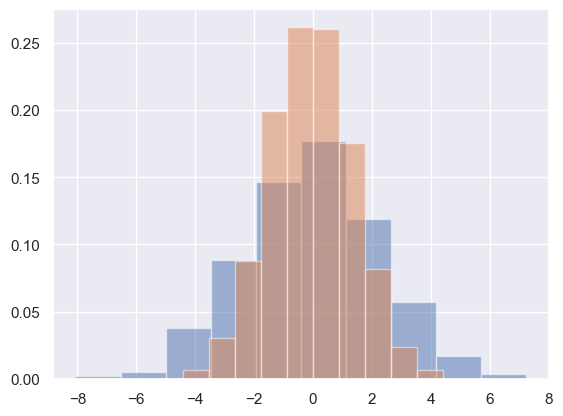

In [2]:
data = np.random.multivariate_normal([0,0],[[5,2],[2,2]],size=2000)
data = pd.DataFrame(data,columns=['x','y'])

for col in 'xy':
    plt.hist(data[col],density=True,alpha=0.5)

C:\Users\benkh\AppData\Local\Temp\ipykernel_4240\1607286097.py:1: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(data=data,shade=True)


<Axes: ylabel='Density'>

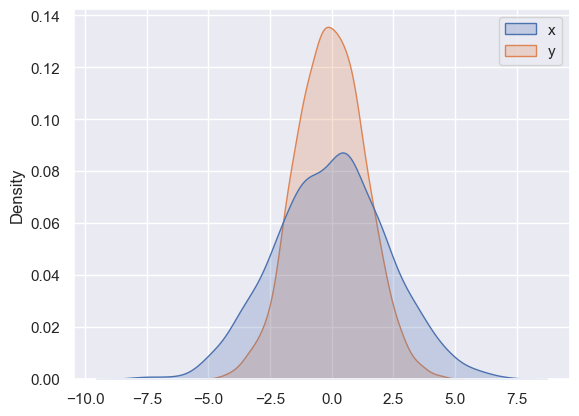

In [3]:
sns.kdeplot(data=data,shade=True)

<Axes: xlabel='x', ylabel='y'>

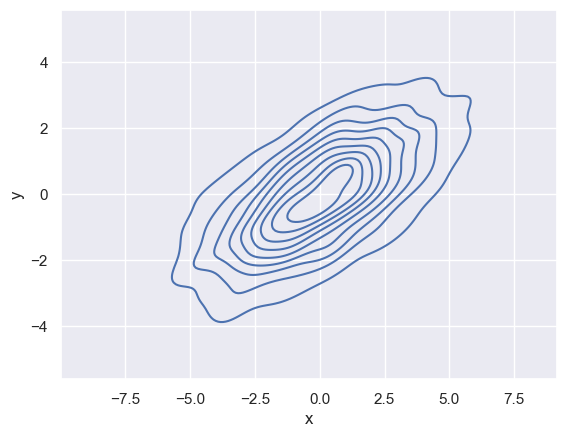

In [4]:
sns.kdeplot(data=data,x='x',y='y')

In [5]:
iris = sns.load_dataset('iris')
iris.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


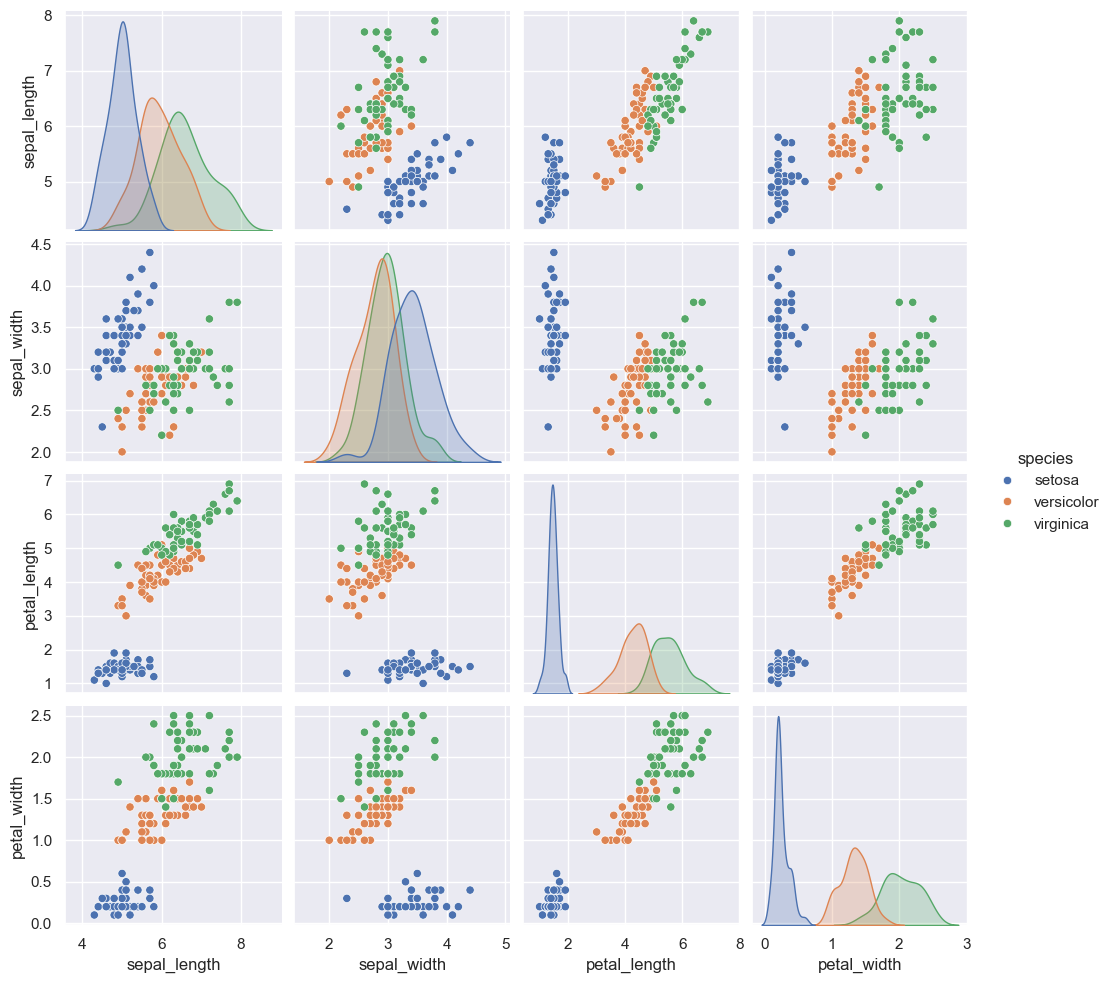

In [6]:
sns.pairplot(iris,hue='species',height=2.5)

In [7]:
tips = sns.load_dataset('tips')
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


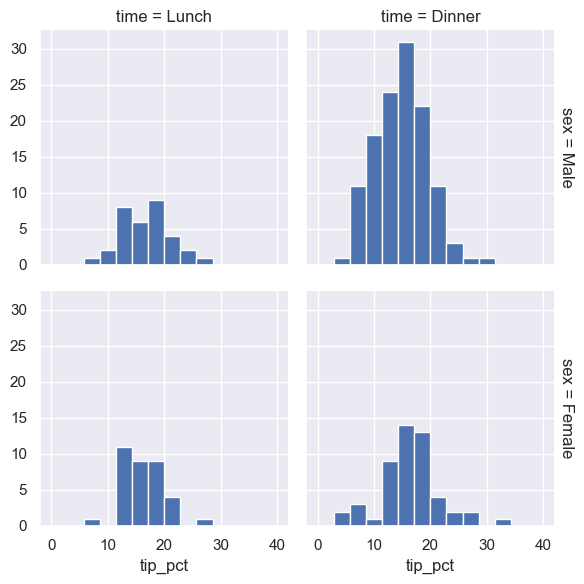

In [8]:
tips['tip_pct'] = 100 * tips['tip'] / tips['total_bill']

grid = sns.FacetGrid(tips, row='sex', col='time', margin_titles=True)
grid.map(plt.hist, "tip_pct", bins=np.linspace(0, 40, 15))

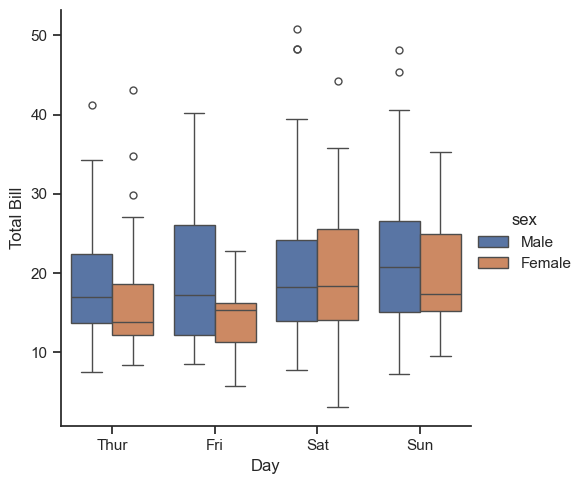

In [9]:
with sns.axes_style (style='ticks'):
    g= sns.catplot(x="day",y="total_bill",hue="sex",
                   data=tips,kind="box")
    g.set_axis_labels("Day","Total Bill")

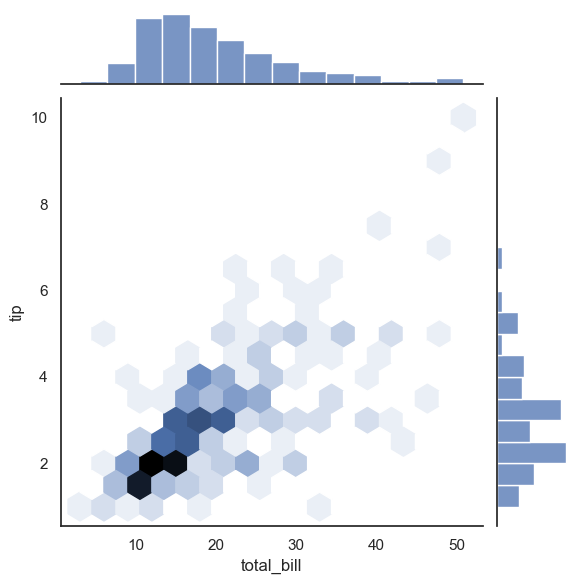

In [10]:
with sns.axes_style('white'):
    sns.jointplot(x="total_bill",y="tip",data=tips,kind='hex')

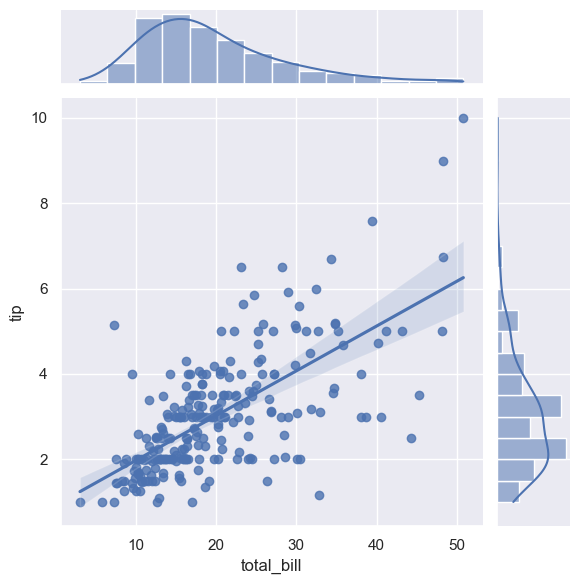

In [11]:
sns.jointplot(x="total_bill",y="tip",data=tips,kind='reg')

In [12]:
planets = sns.load_dataset('planets')
planets.head()

,method,number,orbital_period,mass,distance,year
0,Radial Velocity,1,269.300,7.10,77.40,2006
1,Radial Velocity,1,874.774,2.21,56.95,2008
2,Radial Velocity,1,763.000,2.60,19.84,2011
3,Radial Velocity,1,326.030,19.40,110.62,2007
4,Radial Velocity,1,516.220,10.50,119.47,2009


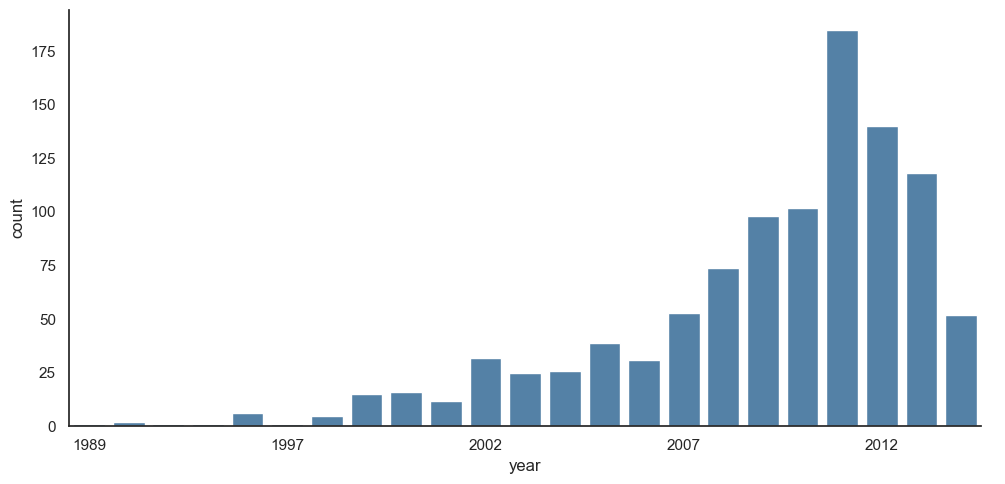

In [13]:
with sns.axes_style('white'):
    g= sns.catplot(x="year",data=planets,aspect=2,
                   kind="count",color='steelblue')
    g.set_xticklabels(step=5)

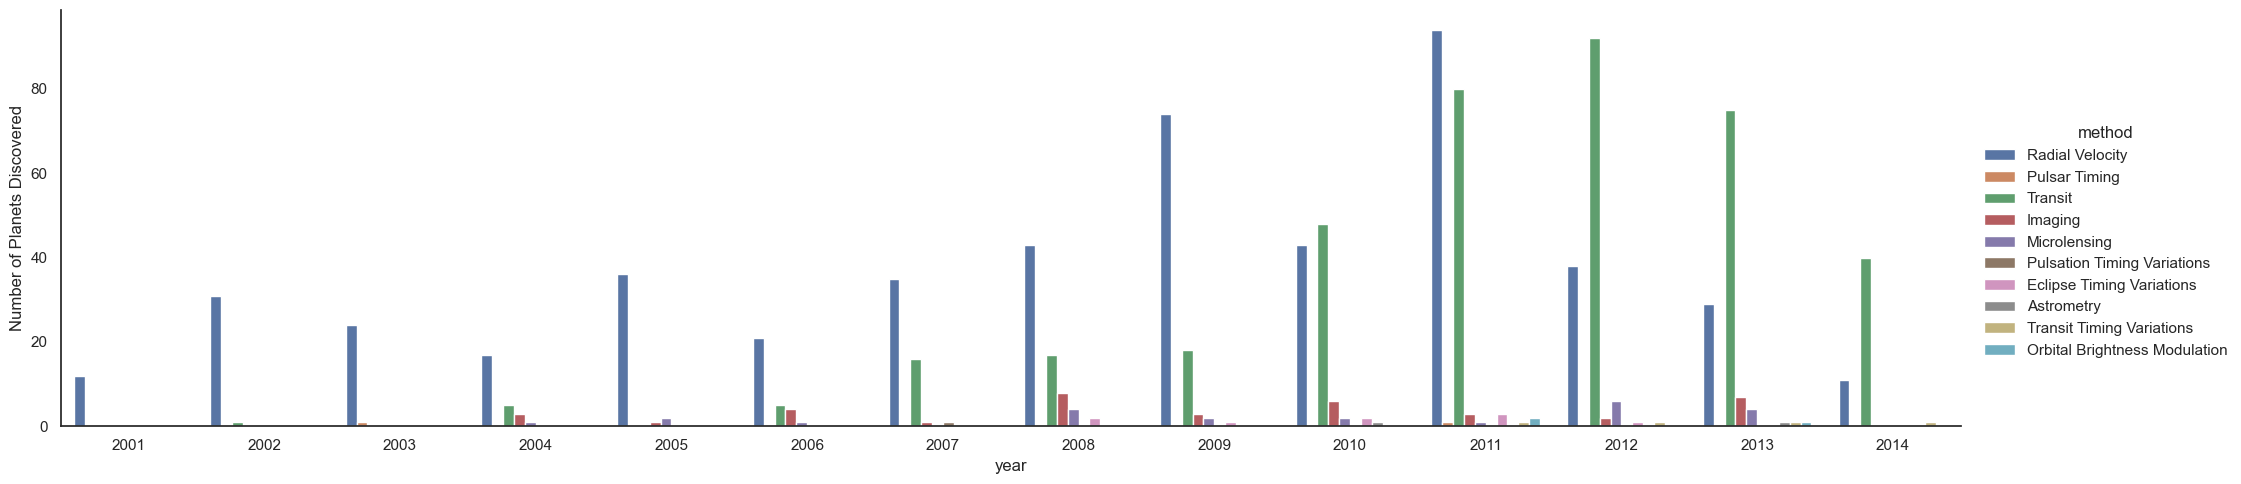

In [14]:
with sns.axes_style('white'):
    g =sns.catplot(x="year",data=planets,aspect=4.0,kind='count',
                   hue='method',order=range(2001,2015))
    g.set_ylabels('Number of Planets Discovered')

In [15]:
data = pd.read_csv(r"C:\Users\benkh\Python_Handbook\Handbook\Python_DataScience_Handbook\data\marathon-data.csv")
data.head()

,age,gender,split,final
0,33,M,01:05:38,02:08:51
1,32,M,01:06:26,02:09:28
2,31,M,01:06:49,02:10:42
3,38,M,01:06:16,02:13:45
4,31,M,01:06:32,02:13:59


In [16]:
data.dtypes

age        int64
gender    object
split     object
final     object
dtype: object

In [17]:
import datetime 
def convert_time(s):
    h,m,s =map(int,s.split(':'))
    return datetime.timedelta(hours=h,minutes=m,seconds=s)
data = pd.read_csv(r"C:\Users\benkh\Python_Handbook\Handbook\Python_DataScience_Handbook\data\marathon-data.csv",converters={'split':convert_time,'final':convert_time})
data.head()


,age,gender,split,final
0,33,M,0 days 01:05:38,0 days 02:08:51
1,32,M,0 days 01:06:26,0 days 02:09:28
2,31,M,0 days 01:06:49,0 days 02:10:42
3,38,M,0 days 01:06:16,0 days 02:13:45
4,31,M,0 days 01:06:32,0 days 02:13:59


In [18]:
data.dtypes

age                 int64
gender             object
split     timedelta64[ns]
final     timedelta64[ns]
dtype: object

In [19]:
data['split_sec'] = data['split'].view(int)/1E9
data['final_sec'] = data['final'].view(int)/1E9
data.head()

C:\Users\benkh\AppData\Local\Temp\ipykernel_4240\3926557446.py:1: FutureWarning: Series.view is deprecated and will be removed in a future version. Use ``astype`` as an alternative to change the dtype.
  data['split_sec'] = data['split'].view(int)/1E9
C:\Users\benkh\AppData\Local\Temp\ipykernel_4240\3926557446.py:2: FutureWarning: Series.view is deprecated and will be removed in a future version. Use ``astype`` as an alternative to change the dtype.
  data['final_sec'] = data['final'].view(int)/1E9


,age,gender,split,final,split_sec,final_sec
0,33,M,0 days 01:05:38,0 days 02:08:51,3938.0,7731.0
1,32,M,0 days 01:06:26,0 days 02:09:28,3986.0,7768.0
2,31,M,0 days 01:06:49,0 days 02:10:42,4009.0,7842.0
3,38,M,0 days 01:06:16,0 days 02:13:45,3976.0,8025.0
4,31,M,0 days 01:06:32,0 days 02:13:59,3992.0,8039.0


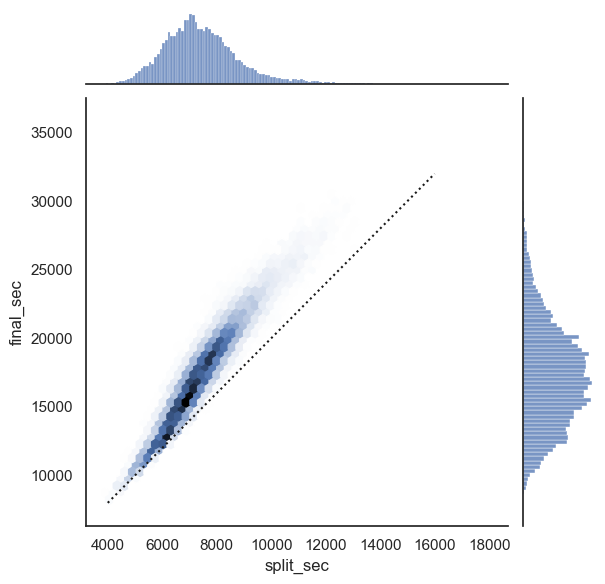

In [20]:
with sns.axes_style('white'):
    g = sns.jointplot(x='split_sec',y='final_sec',data=data,kind='hex')
    g.ax_joint.plot(np.linspace(4000,16000),np.linspace(8000,32000),':k')

In [21]:
data['split_frac'] = 1-2*data['split_sec'] / data['final_sec']
data.head()

,age,gender,split,final,split_sec,final_sec,split_frac
0,33,M,0 days 01:05:38,0 days 02:08:51,3938.0,7731.0,-0.018756
1,32,M,0 days 01:06:26,0 days 02:09:28,3986.0,7768.0,-0.026262
2,31,M,0 days 01:06:49,0 days 02:10:42,4009.0,7842.0,-0.022443
3,38,M,0 days 01:06:16,0 days 02:13:45,3976.0,8025.0,0.009097
4,31,M,0 days 01:06:32,0 days 02:13:59,3992.0,8039.0,0.006842


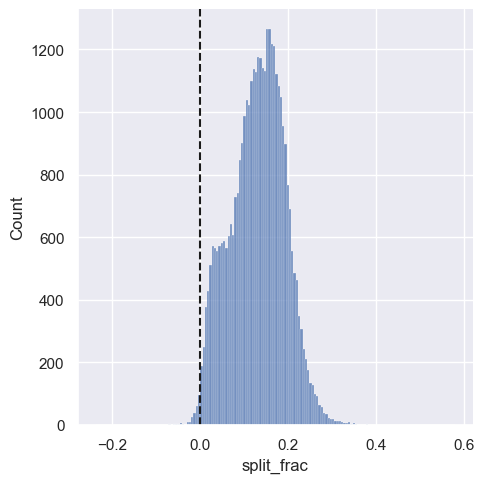

In [22]:
sns.displot(data['split_frac'],kde=False)
plt.axvline(0,color='k',linestyle='--')

In [23]:
sum (data.split_frac<0)

251

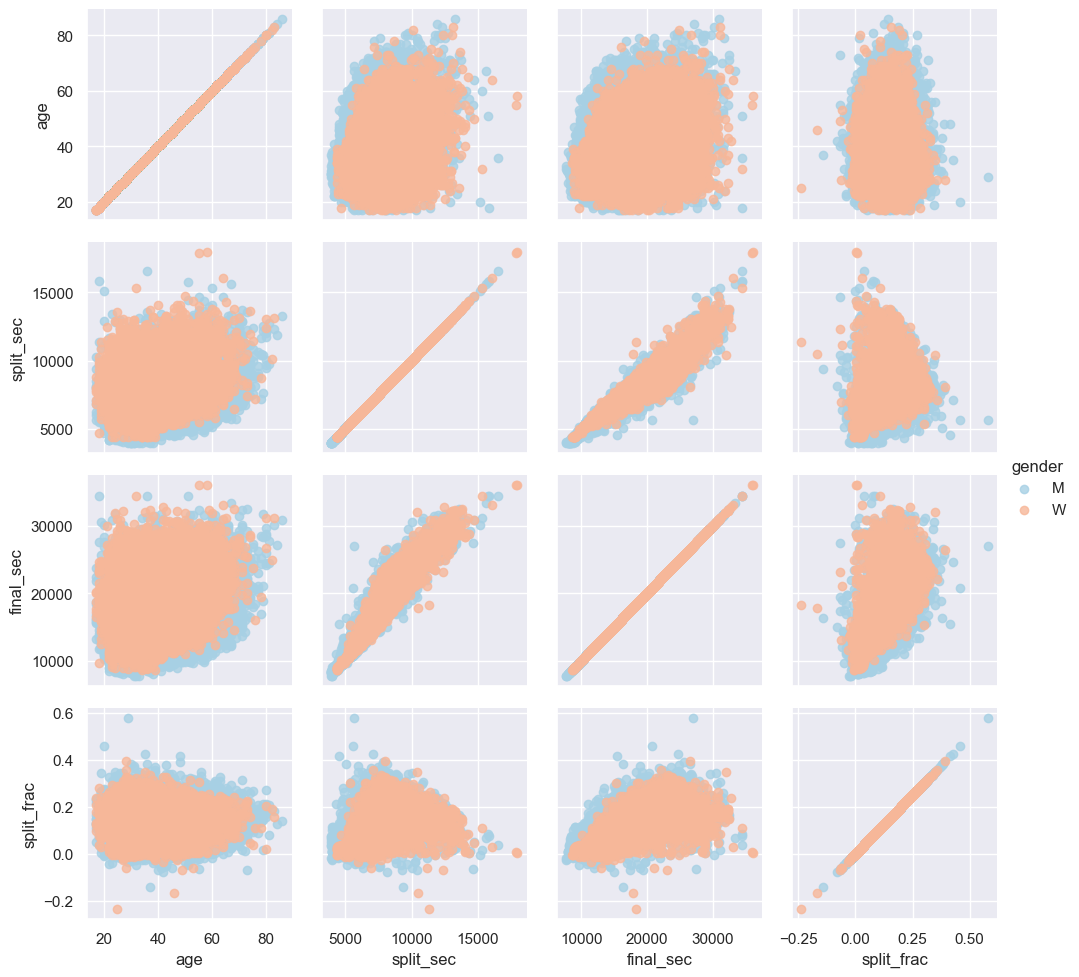

In [24]:
g = sns.PairGrid(data,vars=['age','split_sec','final_sec','split_frac'],hue='gender',palette='RdBu_r')
g.map(plt.scatter,alpha=0.8)
g.add_legend()

C:\Users\benkh\AppData\Local\Temp\ipykernel_4240\3676383389.py:1: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(data.split_frac[data.gender=='M'],label='men',shade=True)
C:\Users\benkh\AppData\Local\Temp\ipykernel_4240\3676383389.py:2: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(data.split_frac[data.gender =='W'],label='women',shade=True)


Text(0.5, 0, 'split_frac')

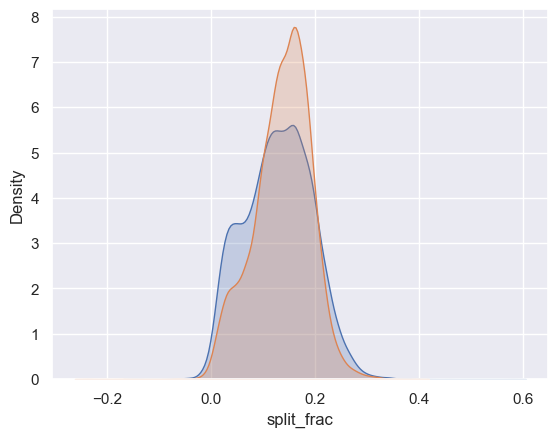

In [25]:
sns.kdeplot(data.split_frac[data.gender=='M'],label='men',shade=True)
sns.kdeplot(data.split_frac[data.gender =='W'],label='women',shade=True)
plt.xlabel('split_frac')

C:\Users\benkh\AppData\Local\Temp\ipykernel_4240\2655927384.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x="gender",y="split_frac",data=data,palette=["lightblue","lightpink"])


<Axes: xlabel='gender', ylabel='split_frac'>

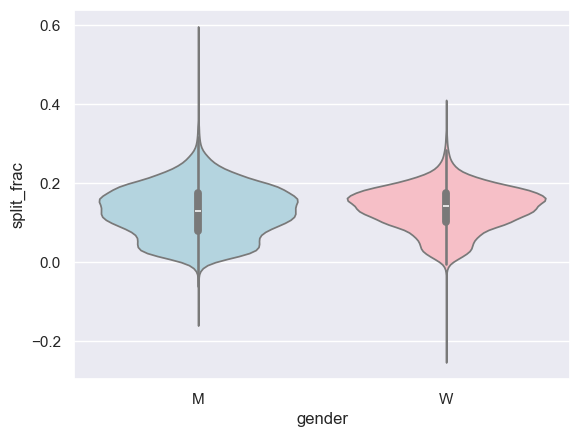

In [26]:
sns.violinplot(x="gender",y="split_frac",data=data,palette=["lightblue","lightpink"])

In [27]:
data['age_dec'] = data.age.map(lambda age:10*(age//10))
data.head()

,age,gender,split,final,split_sec,final_sec,split_frac,age_dec
0,33,M,0 days 01:05:38,0 days 02:08:51,3938.0,7731.0,-0.018756,30
1,32,M,0 days 01:06:26,0 days 02:09:28,3986.0,7768.0,-0.026262,30
2,31,M,0 days 01:06:49,0 days 02:10:42,4009.0,7842.0,-0.022443,30
3,38,M,0 days 01:06:16,0 days 02:13:45,3976.0,8025.0,0.009097,30
4,31,M,0 days 01:06:32,0 days 02:13:59,3992.0,8039.0,0.006842,30


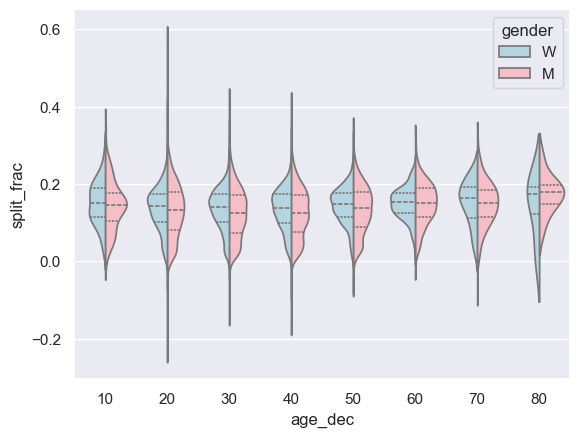

In [28]:
men = (data.gender =='M')
women = (data.gender == 'W')

with sns.axes_style(style=None):
    sns.violinplot(x="age_dec",y="split_frac",hue="gender",data=data,split=True,inner="quartile",
                   palette = ["lightblue","lightpink"])

In [ ]:
g = sns.lmplot(x= 'final_sec',y= 'split_frac',col='gender',data=data,markers=".",scatter_kws = dict(color='c'))
g.map(plt